In [1]:
import os
import pickle
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# 1. Paths Setup
# Since this notebook lives in D:\Capstoneproject2-EV\notebooks
NOTEBOOK_DIR = os.getcwd()
ROOT_DIR = os.path.dirname(NOTEBOOK_DIR)

# 2. Locate and load model & feature schema
# Check both notebooks folder and project root folder
model_path = (
    "best_ev_classification_model.pkl"
    if os.path.exists("best_ev_classification_model.pkl")
    else os.path.join(ROOT_DIR, "best_ev_classification_model.pkl")
)
features_path = (
    "classification_model_features.pkl"
    if os.path.exists("classification_model_features.pkl")
    else os.path.join(ROOT_DIR, "classification_model_features.pkl")
)

with open(model_path, "rb") as f:
    model = pickle.load(f)

with open(features_path, "rb") as f:
    feature_names = pickle.load(f)

print(f"Loaded model successfully: {type(model).__name__}")
print(f"Total features expected: {len(feature_names)}")

# 3. Load dataset to extract real evaluation samples
csv_path = (
    os.path.join(ROOT_DIR, "cleaned_charging_records.csv")
    if os.path.exists(os.path.join(ROOT_DIR, "cleaned_charging_records.csv"))
    else "cleaned_charging_records.csv"
)
df = pd.read_csv(csv_path)

# Cyclical encoding for Hour
if "Hour" in df.columns:
    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24.0)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24.0)

# Align dummy variables with training schema
df_encoded = pd.get_dummies(df, drop_first=True)
X_data = df_encoded.reindex(columns=feature_names, fill_value=0)

# Take 200 samples for fast, responsive calculation
X_sample = X_data.iloc[:200]
print(f"Sample data aligned with shape: {X_sample.shape}")

Loaded model successfully: XGBClassifier
Total features expected: 22
Sample data aligned with shape: (200, 22)


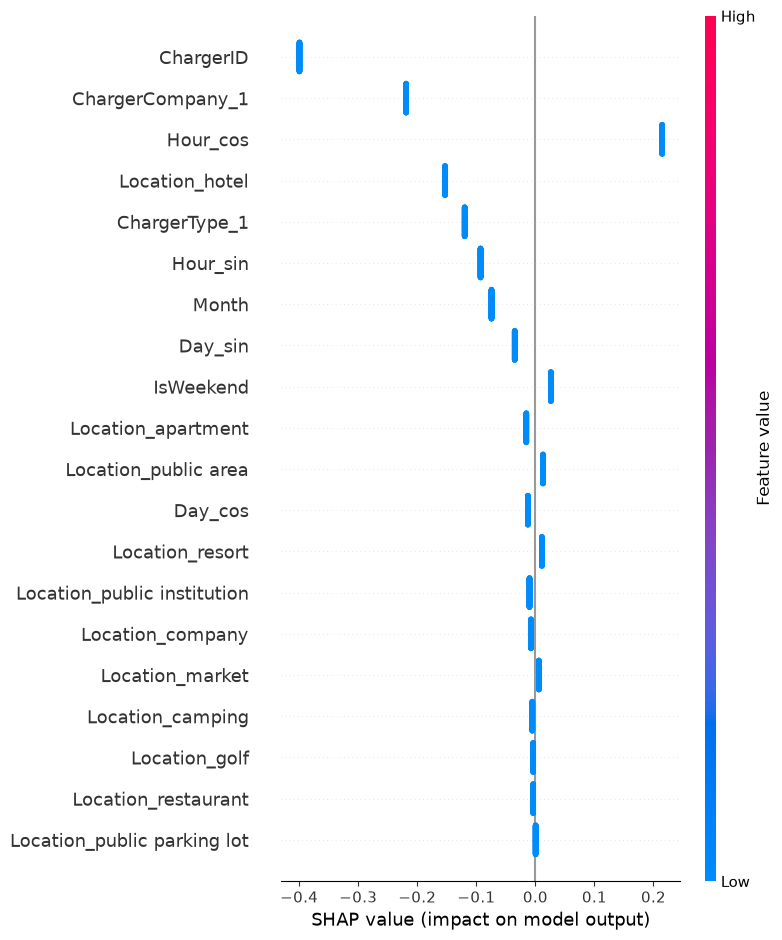

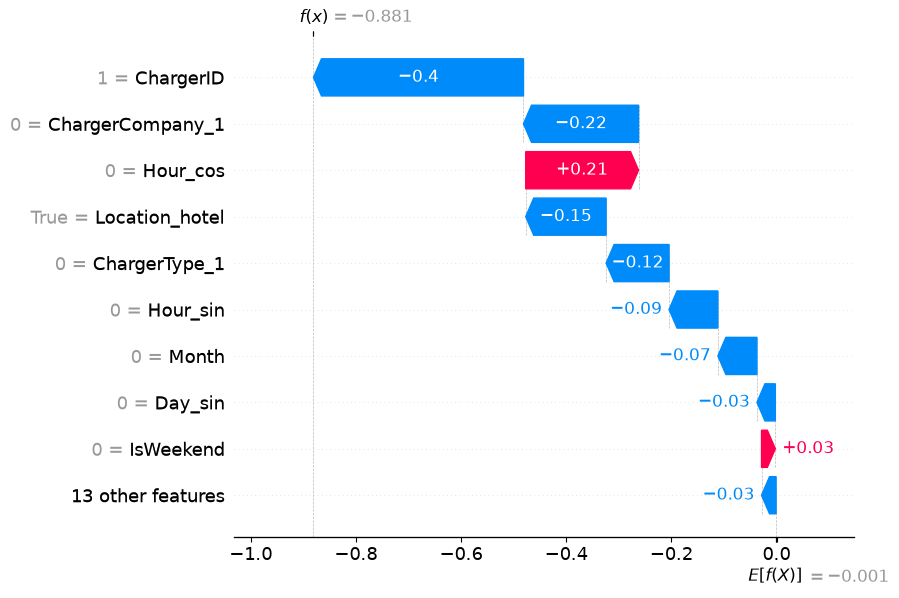

In [2]:
####SHAP Plots
explainer_shap = shap.TreeExplainer(model)
shap_values = explainer_shap(X_sample)

# Global Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, show=True)

# Local Waterfall Plot (Session 0)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[0], show=True)

Explaining session index: 446
Surge Probability: 42.53%


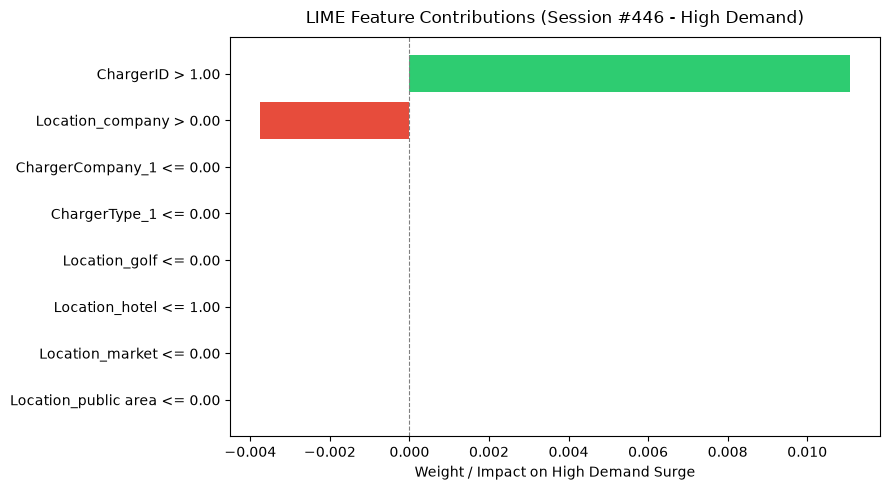

In [8]:
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Ensure the background matrix is strictly float32
bg_df = X_data.iloc[:500].astype(np.float32)

# 2. Prediction wrapper: enforce float32 DataFrame with original feature names
predict_fn = lambda x: model.predict_proba(
    pd.DataFrame(x, columns=feature_names).astype(np.float32)
)

# 3. Select an instance with a high surge probability
probs = predict_fn(bg_df.values)[:, 1]
target_idx = int(np.argmax(probs))

print(f"Explaining session index: {target_idx}")
print(f"Surge Probability: {probs[target_idx]:.2%}")

# 4. Initialize LIME Tabular Explainer
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=bg_df.values,
    feature_names=feature_names,
    class_names=["Normal Demand", "High Demand"],
    mode="classification",
    random_state=42,
)

# 5. Generate explanation for the High Demand class (Class 1)
exp = explainer_lime.explain_instance(
    data_row=bg_df.iloc[target_idx].values,
    predict_fn=predict_fn,
    num_features=8,
    labels=(1,),
)

# 6. Extract weights and render a Matplotlib horizontal bar chart
weights = exp.as_list(label=1)
labels = [item[0] for item in weights]
scores = [item[1] for item in weights]

plt.figure(figsize=(9, 5))
bar_colors = ["#2ecc71" if val > 0 else "#e74c3c" for val in scores]
plt.barh(labels[::-1], scores[::-1], color=bar_colors[::-1])
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title(
    f"LIME Feature Contributions (Session #{target_idx} - High Demand)",
    fontsize=12,
    pad=10,
)
plt.xlabel("Weight / Impact on High Demand Surge")
plt.tight_layout()
plt.show()